In [61]:
import numpy as np


class LinearRegression:
    def __init__(self, learning_rate, n_iterations, fit_intercept=True):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.fit_intercept = fit_intercept

        self.weights = None
        self.intercept = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples = X.shape[0]

        y = y.reshape(-1, 1)

        if self.fit_intercept:
            n_samples = X.shape[0]
            intercept_col = np.ones((n_samples, 1))
            X = np.hstack((intercept_col, X))

        n_features = X.shape[1]

        w = np.zeros((n_features, 1))
        self.loss_history = []

        for _ in range(self.n_iterations):
            # предсказание
            y_pred = X @ w

            # MSE
            error = y_pred - y
            mse_loss = np.mean(error**2)
            self.loss_history.append(mse_loss)

            grad = (2 / n_samples) * (X.T @ error)

            w_next = w - self.learning_rate * grad
            w = w_next

        if self.fit_intercept:
            self.intercept = float(w[0, 0])
            self.weights = w[1:, 0]
        else:
            self.intercept = 0.0
            self.weights = w[:, 0]

        return self

    def predict(self, X):
        predictions = X @ self.weights + self.intercept
        return predictions


def mse(y_true, y_pred):
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()
    return float(np.mean((y_true - y_pred) ** 2))


def mae(y_true, y_pred):
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()
    return float(np.mean(np.abs(y_true - y_pred)))


def r2(y_true, y_pred):
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    return float(1 - (ss_res / ss_tot))

(150, 1)
(150,)


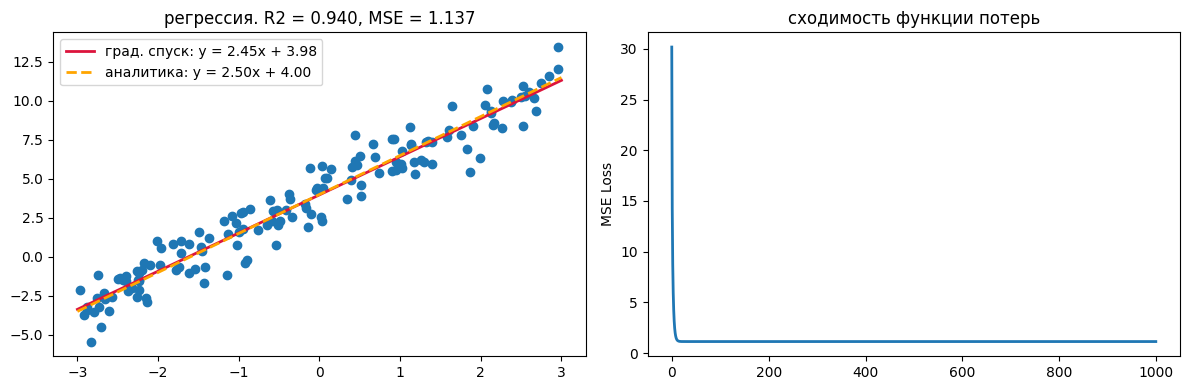

In [62]:
import matplotlib.pyplot as plt


# y = 2.5*x + 4.0 + шум
n_samples = 150
X = np.random.uniform(-3, 3, size=(n_samples, 1))
true_w, true_b = 2.5, 4
noise = np.random.normal(0, 1, size=(n_samples, 1))
y = true_w * X + true_b + noise

model = LinearRegression(learning_rate=0.1, n_iterations=1000, fit_intercept=True)
model.fit(X, y)
y_pred = model.predict(X)

# аналитика
X_ext = np.hstack((np.ones((n_samples, 1)), X))
w_analytical = np.linalg.inv(X_ext.T @ X_ext) @ X_ext.T @ y

mse = mse(y, y_pred)
r2 = r2(y, y_pred)

_, (ax_data, ax_loss) = plt.subplots(1, 2, figsize=(12, 4))


x_line = np.linspace(-3, 3, 200).reshape(-1, 1)
y_pred_line = model.predict(x_line)
y_true_line = true_w * x_line + true_b

ax_data.set_title(f"регрессия. R2 = {r2:.3f}, MSE = {mse:.3f}")

ax_data.scatter(X, y)
ax_data.plot(
    x_line,
    y_pred_line,
    color="crimson",
    linewidth=2,
    label=f"град. спуск: y = {model.weights[0]:.2f}x + {model.intercept:.2f}",
)
ax_data.plot(
    x_line,
    y_true_line,
    linestyle="--",
    color="orange",
    linewidth=2,
    label=f"аналитика: y = {true_w:.2f}x + {true_b:.2f}",
)
ax_data.legend()


ax_loss.plot(model.loss_history, linewidth=2)
ax_loss.set_title("сходимость функции потерь")
ax_loss.set_ylabel("MSE Loss")

plt.tight_layout()
plt.show()